In [ ]:
#TODO
##1 Get information from Google Sheet, authentication, etc etc

##2 Go through each document and extract text, page by page

##ERROR handling: 
# link not found (only name exists, forgot to copy over name)
# text cannot be extracted (may need OCR)

##3 When language is not English, translate
## ERROR handling:
#Problem with API
#Problem with ChatGPT

##4 Store translation in same location as original document
# 4.25 json file of array of pages (do anyway) and/or raw text (harder to read)
# 4.5 Save link on spreadsheet (how difficult is this?) 


##5 Create json file with all documents, extracted by page and translated

##6 Tokenize to split by sentences

In [1]:
## Imports
import fitz

from oauth2client.service_account import ServiceAccountCredentials
import gspread
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

import re
import io
import json
import os 
from time import sleep

import openai
from openai import OpenAI

import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /Users/modekurt/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
/Users/modekurt/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/var/folders/h1/_zymb6k15855dxzmpdj7099w0000gp/T/ipykernel_18010/3738534372.py:20: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


### Download Documents and Extract text into "all_plans_text.json"

In [2]:
### Function to read information from Google Sheet
"""Retrieve PDF document links from Google Sheets where col K says 'Downloaded' and document language is 'English' """

def read_pdf_from_google_sheets(worksheet_name, sheet_name, col_link, col_doc_status, col_doc_lang, col_doc_relev):
    # Authenticate Google Sheets API
    scope = ['https://spreadsheets.google.com/feeds',
             'https://www.googleapis.com/auth/drive']
    creds = ServiceAccountCredentials.from_json_keyfile_name('wired-method-230918-2e0d79f58fe5.json', scope)
    client = gspread.authorize(creds)

    # Open the Google Sheets file
    sheet = client.open(worksheet_name).worksheet(sheet_name)

    # Get all records from the sheet
    records = sheet.get_all_records()

    # Get data already written to file to prevent repeat extraction
    with open('corpus/all_plans_text.json', 'r') as file:
        data = json.load(file)
    # token_len = {}
    # Iterate over each record
    for record in records:
        if (record[col_doc_status] == 'Downloaded' and record[col_doc_relev] == 1):
            ## TODO: Implement relevance check
            doc_lang = record[col_doc_lang]
            link = record[col_link]
            name = record['Document Name']
            #Error handling
            if not link:
                print(f"Error: Document link not found: {name}")
                continue
            if name in data["english"].keys() or name in data["otherlang"].keys() :
                print(f"Skipped {name}, already extracted")
            else:
                #get file
                fileid = fileid_from_url(link)
                print(name)
                #download file
                content = download_file_from_drive(file_id=fileid)

                #extract text
                orig_text, orig_text_len = extract_text_from_pdf(content)
                    
                ## Error handling
                if orig_text_len == 0:
                    (f"Error: Document not read: {name}")
                if doc_lang == 'English':
                    data["english"][name]= {"original_text" : orig_text, 
                             "original_text_length" : orig_text_len, 
                            }
                else:
                    data["otherlang"][name]= {"original_text" : orig_text, 
                             "original_text_length" : orig_text_len, 
                            }
                
                # Write data to JSON file
                with open('corpus/all_plans_text.json', 'w', encoding='utf-8') as json_file:
                    json.dump(data, json_file, indent=4)


In [3]:
#Functions for downloading Google file and extracting text

### Get Google file id from url
def fileid_from_url(url):
    m = re.search(r"/file/d/([a-zA-Z0-9_-]+)/", url) 
    return m.group(1)

### Download file from Goodle Drive with file id
def download_file_from_drive(file_id):
    """Download a file from Google Drive by file ID and return the binary content."""
    scope = ['https://spreadsheets.google.com/feeds',
             'https://www.googleapis.com/auth/drive',
             'https://www.googleapis.com/auth/drive.readonly']
    creds = ServiceAccountCredentials.from_json_keyfile_name('wired-method-230918-2e0d79f58fe5.json', scope)
    service = build('drive', 'v3', credentials=creds)
    request = service.files().get_media(fileId=file_id)
    fh = io.BytesIO()
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while done is False:
        status, done = downloader.next_chunk()
    fh.seek(0)
    return fh.read()

In [4]:
### Functions to Extract text from PDF
def extract_text_from_pdf(content):
   with fitz.open(stream=content, filetype="pdf") as doc:
        orig_text = []
        orig_text_len = 0
        for page in doc:
            text = page.get_text("text")
            orig_text_len += len(text)
            orig_text += [text]
        print("Document extracted")
        return orig_text, orig_text_len

In [6]:
## Get All plans and extract text from Master Document List Google Sheet
worksheet_name = 'Data'
sheet_name = 'Master Document List'
col_link = 'Document Link'
col_doc_status = 'Document Status'
col_doc_lang = 'Document Language'
col_doc_relev = 'Relevance Filter'
# output_json = 'corpus/all_plans_text.json'

plan_data = read_pdf_from_google_sheets(worksheet_name, sheet_name, col_link, col_doc_status, col_doc_lang, col_doc_relev)


Skipped 20058-2020-pac_2050_buenos_aires_0.pdf, already extracted
Skipped 20058-2010-cap6_pacc_ba3030.pdf, already extracted
Skipped 20058-2018-Buenos-Aires-Estrategia-de-Resiliencia_2018.pdf, already extracted
Skipped 20058-2015-pacc_2020.pdf, already extracted
Skipped 20059-2020-CDS-Estrategias-de-desarrollo-integral-para-el-area-metropolitana-de-Cordoba.pdf, already extracted
Skipped 20068-2020-plac.pdf, already extracted
Skipped 20075-2018-plan-local-de-accion-al-cambio-climatico-2030.pdf, already extracted
Skipped 20140-2017-Yerevan-GCAP.pdf, already extracted
Skipped 206171-2023-PPS22-036-Climate-Strategy-Document_2022_A5P_16pages_v10.pdf, already extracted
Skipped 206171-2016-adaptwest-regional-adaptation-plan-october-2016 (1).pdf, already extracted
Skipped 206171-2013-CLIMATE CHANGE ADAPTATION PLAN 2013-2015.pdf, already extracted
Skipped 206171-2016-resilient-hills-and-coasts-climate-change-adaption-plan-gen.pdf, already extracted
Skipped 206171-2016-climate_change_adaptation_

### Translate Documents using ChatGPT

In [37]:
#Create batch for translation per document
def write_batch_requests(docname, doc):
        batch_requests = []
        page_num = 0
        if doc["original_text_length"] < 400000 and doc["original_text_length"] > 0:
                for page in doc["original_text"]:
                        prompt = f"Translate the following text to English:\n\n{page}"
                        req = {"custom_id": f"{docname}_{page_num}", 
                        "method": "POST", "url": "/v1/chat/completions", 
                        "body": {"model": "gpt-3.5-turbo-0125", 
                                        "messages": [{"role": "system", 
                                                "content": prompt}],
                                                "max_tokens": 2048,
                                                "temperature": 0}}
                        batch_requests.append(req)
                        page_num += 1
                filename = f'corpus/batches/transbr_{docname}.jsonl'
                file = open(filename, 'w', encoding='utf-8')
                for line in batch_requests:
                        json.dump(line, file)
                        file.write('\n')
                file.close()
                return filename
        else:
               print("Plan too long:", docname)
               return None
        

with open('corpus/all_plans_text.json', 'r', encoding='utf-8') as file:
        data = json.load(file)

otherlang_plans = data["otherlang"]
batches = [write_batch_requests(doc, otherlang_plans[doc]) for doc in otherlang_plans]
batches = [filename for filename in batches if filename != None] #remove None

print(batches[:10])


Plan too long: 20075-2018-plan-local-de-accion-al-cambio-climatico-2030.pdf
Plan too long: 20107-2009-4987_1371815067.pdf
Plan too long: 20144-2016-PACE_FR.pdf
Plan too long: 20305-2015-Plano-de-Acao-Vitoria-Sustentavel-baixa_compressed.pdf
Plan too long: 20272-2021-Plano de Desenvolvimento Sustentável e Ação Climática da Ciudad do Rio de Janeiro (Portuguese).pdf
Plan too long: 20287-2021-Plano De Ação Climática Do Município De São Paulo (Portuguese).pdf
Plan too long: 20439-2023-Propuesta-Plan-de-Accion-Regional-de-Cambio-Climatico-RM.pdf
Plan too long: 20480-2022-2022030511255466.pdf
Plan too long: 20524-2021-b18ae3fde5ee48f0824155ba609d6cad.pdf
Plan too long: 20551-2020-P020220728639205645132.pdf
Plan too long: 20546-2020-rB406mNts6qAZtvsAA2tpKUtHUs244.pdf
Plan too long: 20553-2021-P020211209375973407031.pdf
Plan too long: 20564-2022-5d96f73b704045c0b854e2600829a1d7.pdf
Plan too long: 20677-2021-P020211117333538986966.pdf
Plan too long: 20837-2021-Plan-de-Accio769_n-Clima76

In [7]:
#OpenAI Batch Helper Functions
client = OpenAI(
    api_key = os.environ["OPENAI_API_KEY"]
)

def upload_batchfile(batchfile):
  batch_input_file = client.files.create(
    file=open(batchfile, "rb"),
    purpose="batch"
  )
  return batch_input_file.id

def create_batch(batch_input_file_id):
  response = client.batches.create(
    input_file_id=batch_input_file_id,
    endpoint="/v1/chat/completions",
    completion_window="24h",
    metadata={
      "description": "translation"
    }
)
  return response

def get_batch_status(batch_id):
    print(batch_id)
    batch_job = client.batches.retrieve(batch_id)
    return batch_job.status, batch_job.output_file_id

def get_batch_responses(output_file_id):
      response = client.files.content(output_file_id).text.splitlines()
      results = []
      for line in response:
            results += [json.loads(line.strip())]
      return results


In [8]:
#Functions to translate using ChatGPT
def translate_text(text):
    prompt = f"Translate the following text to English:\n\n{text}"
 
    try:
        response = client.chat.completions.create(
            model="gpt-3.5-turbo",
            messages=[{"role": "user",
                    "content": prompt}],
            max_tokens=2048, 
            temperature=0.2,
        )
    except openai.APIConnectionError as e:
        print("Error: The server could not be reached")
        print('Unable to translate:', text[:100])
        print(e.__cause__)  # an underlying Exception, likely raised within httpx.
        return
    except openai.RateLimitError as e:
        print("Error: 429 status code was received")
        print('Unable to translate:', text[:100])
        print(e.__cause__)
        return
    except:
        print('Error: Another ChatGPT problem:')
        print('Unable to translate:', text[:100])
        print(response)
        return 
    else:
        return response.choices[0].message.content

#Helper function to extract and consolidate text from batch responses
def extract_text(responses):
       pages = []
       doc_name = responses[0]["custom_id"].split(".pdf")[0]+".pdf"
       print(doc_name)
       for line in responses:
                if line["response"]["status_code"] == 200:
                       content = line["response"]["body"]["choices"][0]["message"]["content"]
                       page_num = line["custom_id"].split("_")[-1].strip()
                #        print(page_num)
                #        print(content)
                       pages.insert(int(page_num), content)
       return pages, doc_name

In [ ]:
### Code to send batch jobs

# Get list of all docs to be translated (under 400k tokens)
with open('corpus/all_plans_text.json', 'r', encoding='utf-8') as file:
        data = json.load(file)
        file.close()
otherlang_plans = data["otherlang"]
docs_to_translate = [doc for doc in otherlang_plans 
                     if otherlang_plans[doc]["original_text_length"] < 400000 and otherlang_plans[doc]["original_text_length"] > 0]
# print(docs_to_translate[:3])

#Get list of docs which have alread been translated
with open('corpus/all_plans_translated_text.json', 'r', encoding='utf-8') as file:
        translated_text = json.load(file)
        file.close()
translated_docs = [doc for doc in translated_text]

# Check which docs have already been translated
for doc in docs_to_translate:
  if doc not in translated_docs:
       batchfile = f'corpus/batches/transbr_{doc}.jsonl'
       fileid = upload_batchfile(batchfile)
       response = create_batch(fileid)
       with open('corpus/sent_batches.txt', 'a', encoding='utf-8') as file:
             file.write(response.id+"\n")
             file.close()
       print(f"Batch {response.id} sent for {doc}")
       sleep(60)      

In [ ]:
#### Code to get batch responses and extract translations

#Get list of batch_ids
with open('corpus/sent_batches.txt', 'r') as file:
        sent_batch_ids = [line.strip() for line in file] # if line.strip()]
        ##TODO: Add line to remove sent_batches just read from file (or do this manually)
print(sent_batch_ids)

#Get translated text
with open('corpus/all_plans_translated_text.json', 'r', encoding='utf-8') as file:
        translated_text = json.load(file)
        file.close()

#3. Check batch id status & extract translated text
for batch_id in sent_batch_ids:
        status, output_file = get_batch_status(batch_id)
        #4. If batch done, retrieve text and put into all_text document 
        if status == 'completed':
               responses = get_batch_responses(output_file)
               print("Got reponses")
               pages, doc_name = extract_text(responses)
               translated_text[doc_name] = pages
        
# Store translated text
with open('corpus/all_plans_translated_text.json', 'w', encoding='utf-8') as file:
        json.dump(translated_text, file)
        file.close()          

In [ ]:
#Restructure the data
with open('corpus/all_plans_translated_text.json', 'r', encoding='utf-8') as file:
       t_data = json.load(file)
    
#add in pdf 

In [3]:
#Quick stats on documents to translate
with open('corpus/all_plans_text_OFFICIAL.json', 'r', encoding='utf-8') as file:
        data = json.load(file)

with open('corpus/all_plans_translated_text.json', 'r', encoding='utf-8') as file:
       t_data = json.load(file)

docs_otherlang = data["otherlang"]
docs_english = data["english"]
error_docs = [doc for doc in docs_otherlang if docs_otherlang[doc]["original_text_length"] == 0 ]
doc_lengths = pd.DataFrame([docs_otherlang[doc]["original_text_length"] for doc in docs_otherlang])

print("# of English Documents:", len(docs_english))
print("# of Documents to translate:", len(docs_otherlang))
print("# of Documents alread translated:", len(t_data))
print("# of Documents with errors:", len(error_docs))
print("Documents with errors:", error_docs)
print("Document Token Length stats:", doc_lengths.describe())
print("Total Tokens:", doc_lengths.sum())
print("# Documents with Tokens > 400,000:", len(doc_lengths[doc_lengths[0] > 400000]))

# of English Documents: 321
# of Documents to translate: 292
# of Documents alread translated: 226
# of Documents with errors: 11
Documents with errors: ['20480-2022-2022030511255466.pdf', '20524-2021-b18ae3fde5ee48f0824155ba609d6cad.pdf', '20551-2020-P020220728639205645132.pdf', '20546-2020-rB406mNts6qAZtvsAA2tpKUtHUs244.pdf', '20553-2021-P020211209375973407031.pdf', '20564-2022-5d96f73b704045c0b854e2600829a1d7.pdf', '20677-2021-P020211117333538986966.pdf', '20827-2015-sintesisPMGRD.pdf', '22241-2022-7400202212190008.pdf', '22266-2023-npa_1206218.pdf', '22457-2021-quyet-dinh-5384-qd-ubnd-uy-ban-nhan-dan-tp-ha-noi.pdf']
Document Token Length stats:                   0
count  2.920000e+02
mean   2.169070e+05
std    2.743608e+05
min    0.000000e+00
25%    2.671000e+04
50%    1.320515e+05
75%    3.108712e+05
max    1.858202e+06
Total Tokens: 0    63336858
dtype: int64
# Documents with Tokens > 400,000: 55


                  0
count  6.130000e+02
mean   2.267285e+05
std    2.418776e+05
min    0.000000e+00
25%    6.657300e+04
50%    1.621020e+05
75%    3.032370e+05
max    1.858202e+06


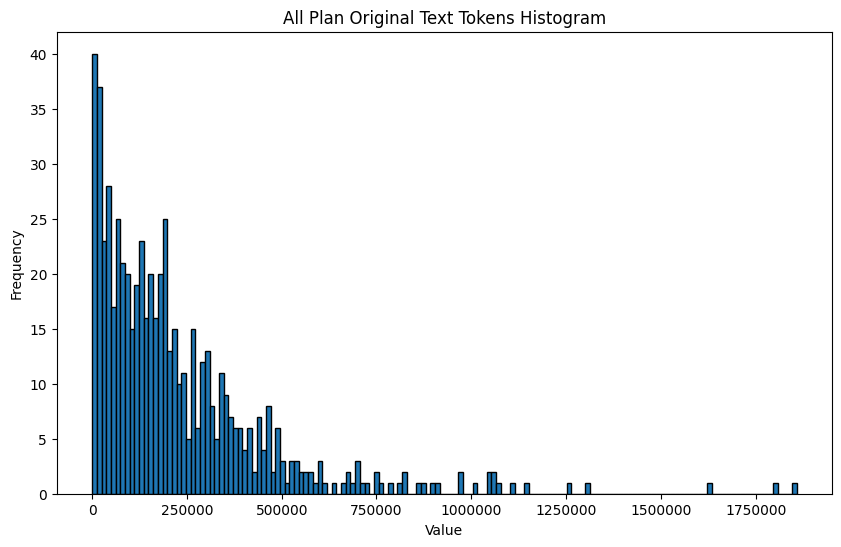

In [43]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

# Function to read numbers from a text file
def read_numbers_from_file(file_path):
    with open(file_path, 'r') as file:
        numbers = [float(line.strip()) for line in file if line.strip()]
    return numbers

# Function to plot histogram
def plot_histogram(numbers, bins=150, title="All Plan Original Text Tokens Histogram", xlabel="Value", ylabel="Frequency"):
    plt.figure(figsize=(10, 6))
    plt.hist(numbers, bins=bins, edgecolor='black')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    
    # Disable scientific notation on x-axis
    plt.gca().xaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    plt.gca().ticklabel_format(style='plain', axis='x')
    # plt.grid(True)
    plt.show()


# Example usage
# file_path = 'corpus/eng_text_char_lens.txt'  # removed 1065350, 912264, 0, 0, replace back
# numbers = read_numbers_from_file(file_path)
english_doc_lengths = [data["english"][doc]["original_text_length"] for doc in data["english"]]
otherlang_doc_lengths = [data["otherlang"][doc]["original_text_length"] for doc in data["otherlang"]]
numbers = english_doc_lengths + otherlang_doc_lengths
numbers_df = pd.DataFrame(numbers) 
print(numbers_df.describe())
plot_histogram(numbers)

In [22]:

### Check text difference using Levenshtein Distance

import Levenshtein

def text_difference_percentage(text1, text2):
    # Calculate the Levenshtein distance between the texts
    distance = Levenshtein.distance(text1, text2)
    
    # Calculate the length of the longer text
    max_length = max(len(text1), len(text2))
    
    # Calculate the percentage difference
    if max_length == 0:
        return 0.0  # Handle edge case where both texts are empty
    else:
        difference_percentage = (distance / max_length) * 100
        return difference_percentage

# Example usage:
with open('corpus/extraction_translation_temp0_seed29_run1.txt', 'r') as f:
    text1 = f.read()
with open("corpus/extraction_translation_temp0_seed29_run2.txt", 'r') as f2:
    text2 = f2.read()

print(text1[:20])
percentage_difference = text_difference_percentage(text1, text2)
print(f"Percentage difference: {percentage_difference:.2f}%")


Changchun City Ecolo
Percentage difference: 7.31%


In [28]:
#Implementing tf-idf
text_json = 'corpus/all_plans_text.json'

#Get all text
with open(text_json, 'r') as file:
    data = json.load(file)
english_plans = data["english"]
corpus = [page for doc in english_plans for page in english_plans[doc]["original_text"]]


vectorizer = TfidfVectorizer()
corpus_tfidf = vectorizer.fit_transform(corpus)

# Display the TF-IDF matrix
df_tfidf = pd.DataFrame(corpus_tfidf.toarray(), columns=vectorizer.get_feature_names_out())

# Sum the TF-IDF scores for each word across all documents
word_sums = df_tfidf.sum(axis=0)

# Sort the words by their total TF-IDF scores
sorted_word_sums = word_sums.sort_values(ascending=False)

# Convert to DataFrame for easier viewing
df_sorted_words = pd.DataFrame(sorted_word_sums, columns=['TF-IDF Score'])

# Print the sorted words (optional)
print(df_sorted_words.head(10))

# Save the sorted words to a CSV file
df_sorted_words.to_csv('corpus/tfidf_all_english_text.csv', index=True)

         TF-IDF Score
the       4896.996547
and       4376.433995
of        3382.199014
to        2878.638235
in        1972.367414
for       1374.383272
city      1269.312261
climate   1219.335619
is         969.575303
energy     898.277551


In [33]:
from nltk import tokenize
import re
#Get extracted text and split into sentences
with open('plans/test/extracted_text.json', 'r') as file:
    data = json.load(file)

data_sentences = {}
for doc_name, doc in data.items():
    pages = []
    for page in doc:
        page = re.sub(r'\n(\d+|-)', r'\n<NEW_SENTENCE>\1', page)
        # print(page)
        sentences = tokenize.sent_tokenize(page)
        sentences = [sentence.split('<NEW_SENTENCE>') for sentence in sentences]
        sentences = [sentence for split_sentences in sentences for sentence in split_sentences] #flatten list of sentences
        sentences = [sentence.replace('\n', '') for sentence in sentences]
        pages += sentences
    data_sentences[doc_name] = pages

with open('plans/test/extracted_text_sentences2.json', 'w', encoding='utf-8') as json_file:
    json.dump(data_sentences, json_file, indent=4)  